In [1]:
import pandas as pd
import numpy as np

# Load Dataset 3
df3 = pd.read_csv(
    r"E:\mlops\UPI-ML-Experiment\datasets\dataset3\upi_transaction_insights_dataset.csv"
)

print("Dataset 3 loaded successfully!")
print("Shape:", df3.shape)

print("\nColumns:")
print(df3.columns.tolist())

print("\nFirst 5 rows:")
display(df3.head())

print("\nData Types:")
print(df3.dtypes)

print("\nMissing Values:")
print(df3.isnull().sum())

Dataset 3 loaded successfully!
Shape: (500, 8)

Columns:
['transaction_id', 'date', 'time', 'amount', 'merchant_category', 'payment_mode', 'location_type', 'is_successful']

First 5 rows:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful
0,TXN100000,2024-09-13,22:02,1399.65,Fuel,QR,Rural,No
1,TXN100001,2024-12-06,11:00,3250.00,Groceries,QR,Urban,Yes
2,TXN100002,2024-05-12,14:53,241.22,Online Services,Contact,Rural,No
3,TXN100003,2024-02-17,22:22,3268.35,Food & Dining,Online,Semi-Urban,Yes
4,TXN100004,2024-06-18,00:11,879.46,Groceries,Contact,Rural,No



Data Types:
transaction_id           str
date                     str
time                     str
amount               float64
merchant_category        str
payment_mode             str
location_type            str
is_successful            str
dtype: object

Missing Values:
transaction_id       0
date                 0
time                 0
amount               0
merchant_category    0
payment_mode         0
location_type        0
is_successful        0
dtype: int64


In [2]:
# ============================================
# DATASET 3 - FEATURE ENGINEERING
# ============================================

df3_processed = df3.copy()

# Convert date and time
df3_processed["date"] = pd.to_datetime(df3_processed["date"])
df3_processed["time"] = pd.to_datetime(
    df3_processed["time"],
    format="%H:%M"
)

# Extract useful time features
df3_processed["year"] = df3_processed["date"].dt.year
df3_processed["month"] = df3_processed["date"].dt.month
df3_processed["day"] = df3_processed["date"].dt.day
df3_processed["day_of_week"] = df3_processed["date"].dt.dayofweek

df3_processed["hour"] = df3_processed["time"].dt.hour
df3_processed["minute"] = df3_processed["time"].dt.minute

# Weekend indicator
df3_processed["is_weekend"] = (
    df3_processed["day_of_week"] >= 5
).astype(int)

# Convert successful status to numeric
df3_processed["is_successful_encoded"] = (
    df3_processed["is_successful"]
    .map({"Yes": 1, "No": 0})
)

print("Feature engineering completed!")
print("New shape:", df3_processed.shape)

display(df3_processed.head())

Feature engineering completed!
New shape: (500, 16)


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,year,month,day,day_of_week,hour,minute,is_weekend,is_successful_encoded
0,TXN100000,2024-09-13,1900-01-01 22:02:00,1399.65,Fuel,QR,Rural,No,2024,9,13,4,22,2,0,0
1,TXN100001,2024-12-06,1900-01-01 11:00:00,3250.00,Groceries,QR,Urban,Yes,2024,12,6,4,11,0,0,1
2,TXN100002,2024-05-12,1900-01-01 14:53:00,241.22,Online Services,Contact,Rural,No,2024,5,12,6,14,53,1,0
3,TXN100003,2024-02-17,1900-01-01 22:22:00,3268.35,Food & Dining,Online,Semi-Urban,Yes,2024,2,17,5,22,22,1,1
4,TXN100004,2024-06-18,1900-01-01 00:11:00,879.46,Groceries,Contact,Rural,No,2024,6,18,1,0,11,0,0


In [3]:
print("Columns after feature engineering:")
print(df3_processed.columns.tolist())

print("\nData types:")
print(df3_processed.dtypes)

print("\nBasic statistics:")
display(df3_processed.describe())

Columns after feature engineering:
['transaction_id', 'date', 'time', 'amount', 'merchant_category', 'payment_mode', 'location_type', 'is_successful', 'year', 'month', 'day', 'day_of_week', 'hour', 'minute', 'is_weekend', 'is_successful_encoded']

Data types:
transaction_id                      str
date                     datetime64[us]
time                     datetime64[us]
amount                          float64
merchant_category                   str
payment_mode                        str
location_type                       str
is_successful                       str
year                              int32
month                             int32
day                               int32
day_of_week                       int32
hour                              int32
minute                            int32
is_weekend                        int64
is_successful_encoded             int64
dtype: object

Basic statistics:


,date,time,amount,year,month,day,day_of_week,hour,minute,is_weekend,is_successful_encoded
count,500,500,500.000000,500.0,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2024-06-28 14:35:31.200000,1900-01-01 12:19:59.280000,2523.668540,2024.0,6.438000,15.164000,3.012000,11.854000,28.748000,0.282000,0.500000
min,2024-01-01 00:00:00,1900-01-01 00:00:00,17.620000,2024.0,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2024-04-02 18:00:00,1900-01-01 06:31:15,1277.352500,2024.0,4.000000,7.000000,1.000000,6.000000,13.000000,0.000000,0.000000
50%,2024-06-27 00:00:00,1900-01-01 12:45:00,2552.815000,2024.0,6.000000,15.000000,3.000000,12.000000,30.000000,0.000000,0.500000
75%,2024-09-25 18:00:00,1900-01-01 18:02:15,3802.867500,2024.0,9.000000,23.250000,5.000000,18.000000,44.000000,1.000000,1.000000
max,2024-12-30 00:00:00,1900-01-01 23:56:00,4973.820000,2024.0,12.000000,31.000000,6.000000,23.000000,59.000000,1.000000,1.000000
std,NaN,NaN,1472.660245,0.0,3.455726,9.070041,1.991932,6.853512,17.510618,0.450424,0.500501


In [4]:
# ============================================
# PREPARE FEATURES
# ============================================

categorical_features = [
    "merchant_category",
    "payment_mode",
    "location_type"
]

numerical_features = [
    "amount",
    "year",
    "month",
    "day",
    "day_of_week",
    "hour",
    "minute",
    "is_weekend",
    "is_successful_encoded"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['amount', 'year', 'month', 'day', 'day_of_week', 'hour', 'minute', 'is_weekend', 'is_successful_encoded']

Categorical features:
['merchant_category', 'payment_mode', 'location_type']


In [5]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor3 = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

X3 = preprocessor3.fit_transform(df3_processed)

print("Dataset 3 preprocessing completed!")
print("Original shape:", df3.shape)
print("Final feature matrix shape:", X3.shape)

Dataset 3 preprocessing completed!
Original shape: (500, 8)
Final feature matrix shape: (500, 26)


In [6]:
# ============================================
# DATASET 3 - ISOLATION FOREST
# ============================================

from sklearn.ensemble import IsolationForest
import time

contamination = 0.05

print("Training Isolation Forest...")

start_time = time.time()

iso_model3 = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    random_state=42,
    n_jobs=-1
)

iso_model3.fit(X3)

train_time = time.time() - start_time

# Prediction
start_time = time.time()

iso_pred3 = iso_model3.predict(X3)

prediction_time = time.time() - start_time

# Convert:
# -1 = anomaly
#  1 = normal
df3_iso = df3.copy()

df3_iso["anomaly"] = (iso_pred3 == -1).astype(int)

# Anomaly score
df3_iso["iso_score"] = -iso_model3.decision_function(X3)

anomaly_count = df3_iso["anomaly"].sum()
anomaly_percentage = anomaly_count / len(df3_iso) * 100

print("\nIsolation Forest Results")
print("========================")
print("Training time:", round(train_time, 4), "seconds")
print("Prediction time:", round(prediction_time, 4), "seconds")
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 2), "%")

print("\nTop 20 anomalies:")
display(
    df3_iso[df3_iso["anomaly"] == 1]
    .sort_values("iso_score", ascending=False)
    .head(20)
)

Training Isolation Forest...

Isolation Forest Results
Training time: 0.2523 seconds
Prediction time: 0.019 seconds
Detected anomalies: 25
Anomaly percentage: 5.0 %

Top 20 anomalies:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,anomaly,iso_score
298,TXN100298,2024-09-01,00:55,4447.94,Food & Dining,QR,Urban,Yes,1,0.022106
164,TXN100164,2024-02-04,23:03,4800.41,Health & Pharmacy,Contact,Rural,No,1,0.017575
166,TXN100166,2024-12-15,08:58,872.00,Bills & Utilities,Contact,Urban,Yes,1,0.014548
227,TXN100227,2024-01-01,22:09,975.80,Shopping,QR,Urban,No,1,0.009882
22,TXN100022,2024-01-01,16:12,4505.80,Shopping,Online,Semi-Urban,No,1,0.008525
159,TXN100159,2024-12-28,20:02,905.87,Groceries,Online,Rural,No,1,0.007203
116,TXN100116,2024-11-16,23:52,3576.14,Other,Contact,Rural,No,1,0.007020
301,TXN100301,2024-11-03,15:00,4703.70,Shopping,AutoPay,Urban,No,1,0.006914
479,TXN100479,2024-01-13,23:21,4534.35,Travel,Contact,Rural,Yes,1,0.006445
225,TXN100225,2024-12-28,12:56,4427.20,Online Services,Contact,Semi-Urban,No,1,0.005577


In [7]:
# ============================================
# DATASET 3 - LOCAL OUTLIER FACTOR
# ============================================

from sklearn.neighbors import LocalOutlierFactor
import time

print("Training LOF...")

start_time = time.time()

lof_model3 = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    novelty=False,
    n_jobs=-1
)

lof_pred3 = lof_model3.fit_predict(X3)

execution_time = time.time() - start_time

df3_lof = df3.copy()

df3_lof["anomaly"] = (lof_pred3 == -1).astype(int)

# Negative means more anomalous
df3_lof["lof_score"] = -lof_model3.negative_outlier_factor_

anomaly_count = df3_lof["anomaly"].sum()
anomaly_percentage = anomaly_count / len(df3_lof) * 100

print("\nLOF Results")
print("===========")
print("Execution time:", round(execution_time, 4), "seconds")
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 2), "%")

print("\nTop 20 LOF anomalies:")
display(
    df3_lof[df3_lof["anomaly"] == 1]
    .sort_values("lof_score", ascending=False)
    .head(20)
)

Training LOF...

LOF Results
Execution time: 0.0528 seconds
Detected anomalies: 25
Anomaly percentage: 5.0 %

Top 20 LOF anomalies:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,anomaly,lof_score
60,TXN100060,2024-12-06,23:49,159.07,Other,Online,Semi-Urban,No,1,1.133284
164,TXN100164,2024-02-04,23:03,4800.41,Health & Pharmacy,Contact,Rural,No,1,1.115217
13,TXN100013,2024-04-01,23:51,1930.19,Other,Online,Rural,No,1,1.093600
301,TXN100301,2024-11-03,15:00,4703.70,Shopping,AutoPay,Urban,No,1,1.089722
298,TXN100298,2024-09-01,00:55,4447.94,Food & Dining,QR,Urban,Yes,1,1.076685
227,TXN100227,2024-01-01,22:09,975.80,Shopping,QR,Urban,No,1,1.075191
252,TXN100252,2024-12-26,00:45,1372.33,Travel,Contact,Semi-Urban,No,1,1.072883
213,TXN100213,2024-01-29,09:18,4807.85,Shopping,Contact,Urban,No,1,1.069463
286,TXN100286,2024-11-29,19:45,4720.50,Fuel,QR,Rural,Yes,1,1.069244
220,TXN100220,2024-03-11,00:57,4201.19,Bills & Utilities,Online,Urban,No,1,1.067587


In [8]:
# ============================================
# DATASET 3 - ONE-CLASS SVM
# ============================================

from sklearn.svm import OneClassSVM
import time

print("Training One-Class SVM...")

start_time = time.time()

ocsvm_model3 = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

ocsvm_model3.fit(X3)

train_time = time.time() - start_time

start_time = time.time()

ocsvm_pred3 = ocsvm_model3.predict(X3)

prediction_time = time.time() - start_time

df3_ocsvm = df3.copy()

df3_ocsvm["anomaly"] = (ocsvm_pred3 == -1).astype(int)

df3_ocsvm["ocsvm_score"] = -ocsvm_model3.decision_function(X3)

anomaly_count = df3_ocsvm["anomaly"].sum()
anomaly_percentage = anomaly_count / len(df3_ocsvm) * 100

print("\nOne-Class SVM Results")
print("=====================")
print("Training time:", round(train_time, 4), "seconds")
print("Prediction time:", round(prediction_time, 4), "seconds")
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 2), "%")

print("\nTop 20 One-Class SVM anomalies:")

display(
    df3_ocsvm[df3_ocsvm["anomaly"] == 1]
    .sort_values("ocsvm_score", ascending=False)
    .head(20)
)

Training One-Class SVM...

One-Class SVM Results
Training time: 0.0033 seconds
Prediction time: 0.0027 seconds
Detected anomalies: 42
Anomaly percentage: 8.4 %

Top 20 One-Class SVM anomalies:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,anomaly,ocsvm_score
164,TXN100164,2024-02-04,23:03,4800.41,Health & Pharmacy,Contact,Rural,No,1,0.084301
452,TXN100452,2024-04-30,21:52,3064.57,Fuel,Online,Urban,Yes,1,0.000451
342,TXN100342,2024-04-28,13:50,187.33,Fuel,QR,Semi-Urban,No,1,0.000440
42,TXN100042,2024-06-27,06:57,33.11,Health & Pharmacy,Contact,Urban,No,1,0.000416
329,TXN100329,2024-12-27,01:12,3332.19,Entertainment,Online,Semi-Urban,No,1,0.000414
348,TXN100348,2024-04-30,21:15,340.25,Other,AutoPay,Urban,No,1,0.000360
55,TXN100055,2024-05-30,23:22,24.25,Health & Pharmacy,QR,Semi-Urban,No,1,0.000327
123,TXN100123,2024-01-01,17:29,4651.69,Food & Dining,Online,Semi-Urban,No,1,0.000316
401,TXN100401,2024-12-20,00:04,1888.85,Shopping,QR,Rural,Yes,1,0.000314
363,TXN100363,2024-04-27,21:45,222.08,Health & Pharmacy,Contact,Urban,Yes,1,0.000305


In [9]:
# ============================================
# DATASET 3 - HBOS
# ============================================

from pyod.models.hbos import HBOS
import time

print("Training HBOS...")

start_time = time.time()

hbos_model3 = HBOS(
    contamination=0.05
)

hbos_model3.fit(X3)

train_time = time.time() - start_time

start_time = time.time()

hbos_pred3 = hbos_model3.predict(X3)

prediction_time = time.time() - start_time

df3_hbos = df3.copy()

df3_hbos["anomaly"] = hbos_pred3

df3_hbos["hbos_score"] = hbos_model3.decision_scores_

anomaly_count = df3_hbos["anomaly"].sum()
anomaly_percentage = anomaly_count / len(df3_hbos) * 100

print("\nHBOS Results")
print("============")
print("Training time:", round(train_time, 4), "seconds")
print("Prediction time:", round(prediction_time, 4), "seconds")
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 2), "%")

print("\nTop 20 HBOS anomalies:")

display(
    df3_hbos[df3_hbos["anomaly"] == 1]
    .sort_values("hbos_score", ascending=False)
    .head(20)
)

Training HBOS...

HBOS Results
Training time: 2.4072 seconds
Prediction time: 0.0005 seconds
Detected anomalies: 25
Anomaly percentage: 5.0 %

Top 20 HBOS anomalies:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,anomaly,hbos_score
311,TXN100311,2024-03-24,04:38,1339.21,Entertainment,Contact,Semi-Urban,No,1,-35.990167
9,TXN100009,2024-09-28,03:22,3566.82,Other,Online,Semi-Urban,No,1,-36.210036
341,TXN100341,2024-07-07,03:55,4283.64,Groceries,Contact,Semi-Urban,No,1,-36.367444
267,TXN100267,2024-10-19,05:54,17.62,Travel,Contact,Semi-Urban,Yes,1,-36.445086
160,TXN100160,2024-07-21,07:21,2587.58,Online Services,AutoPay,Semi-Urban,Yes,1,-36.525963
332,TXN100332,2024-10-20,06:48,2369.41,Other,Contact,Urban,No,1,-36.551802
469,TXN100469,2024-03-24,06:51,3555.17,Other,AutoPay,Rural,Yes,1,-36.582048
199,TXN100199,2024-10-26,02:27,1415.72,Bills & Utilities,AutoPay,Semi-Urban,Yes,1,-36.639276
314,TXN100314,2024-04-14,06:44,2466.76,Health & Pharmacy,Online,Semi-Urban,Yes,1,-36.776850
353,TXN100353,2024-03-23,10:01,2784.56,Food & Dining,QR,Semi-Urban,No,1,-36.778120


In [10]:
# ============================================
# DATASET 3 - Z-SCORE
# ============================================

from scipy.stats import zscore
import numpy as np
import time

print("Running Z-Score anomaly detection...")

start_time = time.time()

amount_zscore = np.abs(
    zscore(df3["amount"])
)

# 1.96 ≈ 95% threshold
# 2.58 ≈ 99%
# 3.0  ≈ common anomaly threshold
threshold = 2.0

z_pred3 = (amount_zscore > threshold).astype(int)

execution_time = time.time() - start_time

df3_zscore = df3.copy()

df3_zscore["z_score"] = amount_zscore
df3_zscore["anomaly"] = z_pred3

anomaly_count = df3_zscore["anomaly"].sum()
anomaly_percentage = anomaly_count / len(df3_zscore) * 100

print("\nZ-Score Results")
print("================")
print("Threshold:", threshold)
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_percentage, 2), "%")
print("Execution time:", round(execution_time, 4), "seconds")

print("\nTop Z-Score anomalies:")

display(
    df3_zscore[df3_zscore["anomaly"] == 1]
    .sort_values("z_score", ascending=False)
    .head(20)
)

Running Z-Score anomaly detection...

Z-Score Results
Threshold: 2.0
Detected anomalies: 0
Anomaly percentage: 0.0 %
Execution time: 0.0008 seconds

Top Z-Score anomalies:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,z_score,anomaly


In [11]:
# ============================================
# DATASET 3 - MODEL COMPARISON
# ============================================

comparison3 = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "LOF",
        "One-Class SVM",
        "HBOS",
        "Z-Score"
    ],
    "Anomalies Detected": [
        df3_iso["anomaly"].sum(),
        df3_lof["anomaly"].sum(),
        df3_ocsvm["anomaly"].sum(),
        df3_hbos["anomaly"].sum(),
        df3_zscore["anomaly"].sum()
    ]
})

comparison3["Anomaly Percentage"] = (
    comparison3["Anomalies Detected"]
    / len(df3)
    * 100
)

display(comparison3)

,Model,Anomalies Detected,Anomaly Percentage
0,Isolation Forest,25,5.0
1,LOF,25,5.0
2,One-Class SVM,42,8.4
3,HBOS,25,5.0
4,Z-Score,0,0.0


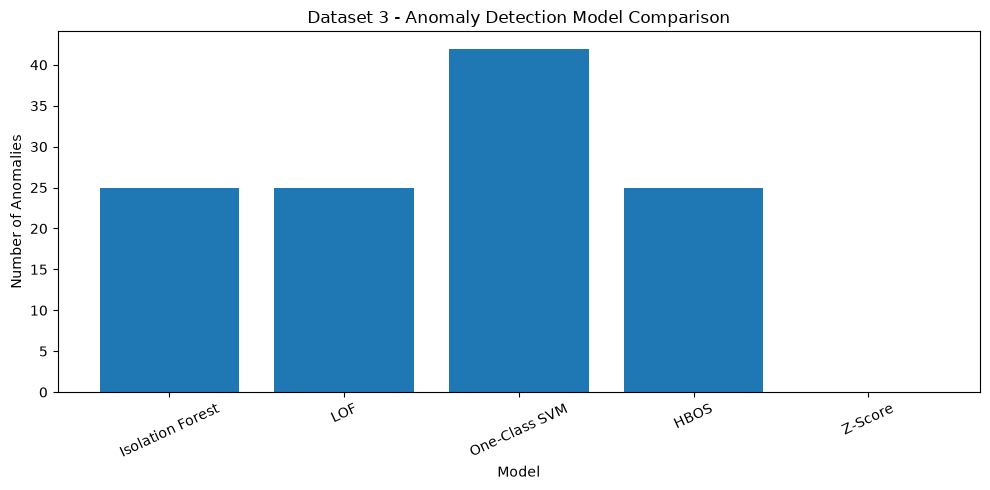

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    comparison3["Model"],
    comparison3["Anomalies Detected"]
)

plt.xlabel("Model")
plt.ylabel("Number of Anomalies")
plt.title("Dataset 3 - Anomaly Detection Model Comparison")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [13]:
# ============================================
# DATASET 3 - ENSEMBLE ANOMALY DETECTION
# ============================================

ensemble3 = df3.copy()

# Rename model predictions
ensemble3["IsolationForest"] = df3_iso["anomaly"].values
ensemble3["LOF"] = df3_lof["anomaly"].values
ensemble3["OneClassSVM"] = df3_ocsvm["anomaly"].values
ensemble3["HBOS"] = df3_hbos["anomaly"].values

# Total number of models identifying anomaly
ensemble3["anomaly_votes"] = (
    ensemble3["IsolationForest"]
    + ensemble3["LOF"]
    + ensemble3["OneClassSVM"]
    + ensemble3["HBOS"]
)

# Final ensemble decision
# 2 or more models must agree
ensemble3["final_anomaly"] = (
    ensemble3["anomaly_votes"] >= 2
).astype(int)

print("======================================")
print("DATASET 3 - ENSEMBLE RESULTS")
print("======================================")

print("\nAnomaly votes distribution:")
print(ensemble3["anomaly_votes"].value_counts().sort_index())

print("\nFinal anomalies detected:")
print(ensemble3["final_anomaly"].sum())

print(
    "Final anomaly percentage:",
    round(
        ensemble3["final_anomaly"].mean() * 100,
        2
    ),
    "%"
)

print("\nTop consensus anomalies:")

display(
    ensemble3[
        ensemble3["final_anomaly"] == 1
    ]
    .sort_values(
        "anomaly_votes",
        ascending=False
    )
    .head(30)
)

DATASET 3 - ENSEMBLE RESULTS

Anomaly votes distribution:
anomaly_votes
0    404
1     78
2     15
3      3
Name: count, dtype: int64

Final anomalies detected:
18
Final anomaly percentage: 3.6 %

Top consensus anomalies:


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,IsolationForest,LOF,OneClassSVM,HBOS,anomaly_votes,final_anomaly
164,TXN100164,2024-02-04,23:03,4800.41,Health & Pharmacy,Contact,Rural,No,1,1,1,0,3,1
159,TXN100159,2024-12-28,20:02,905.87,Groceries,Online,Rural,No,1,1,1,0,3,1
301,TXN100301,2024-11-03,15:00,4703.70,Shopping,AutoPay,Urban,No,1,1,1,0,3,1
22,TXN100022,2024-01-01,16:12,4505.80,Shopping,Online,Semi-Urban,No,1,1,0,0,2,1
24,TXN100024,2024-02-20,23:50,681.18,Fuel,AutoPay,Semi-Urban,Yes,0,1,1,0,2,1
71,TXN100071,2024-08-31,21:17,146.18,Online Services,AutoPay,Rural,Yes,1,0,1,0,2,1
78,TXN100078,2024-04-07,00:54,4498.03,Groceries,QR,Rural,No,1,1,0,0,2,1
166,TXN100166,2024-12-15,08:58,872.00,Bills & Utilities,Contact,Urban,Yes,1,0,1,0,2,1
213,TXN100213,2024-01-29,09:18,4807.85,Shopping,Contact,Urban,No,0,1,1,0,2,1
60,TXN100060,2024-12-06,23:49,159.07,Other,Online,Semi-Urban,No,0,1,1,0,2,1


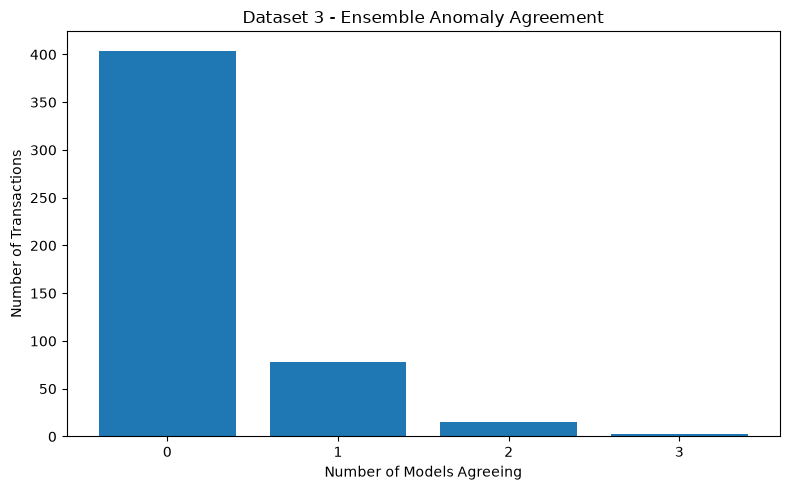

In [14]:
# ============================================
# ENSEMBLE VOTE DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt

vote_counts = (
    ensemble3["anomaly_votes"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    vote_counts.index.astype(str),
    vote_counts.values
)

plt.xlabel("Number of Models Agreeing")
plt.ylabel("Number of Transactions")
plt.title("Dataset 3 - Ensemble Anomaly Agreement")

plt.tight_layout()
plt.show()

In [15]:
# ============================================
# FINAL DATASET 3 COMPARISON
# ============================================

final_comparison3 = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "LOF",
        "One-Class SVM",
        "HBOS",
        "Z-Score",
        "Ensemble"
    ],
    
    "Anomalies Detected": [
        df3_iso["anomaly"].sum(),
        df3_lof["anomaly"].sum(),
        df3_ocsvm["anomaly"].sum(),
        df3_hbos["anomaly"].sum(),
        df3_zscore["anomaly"].sum(),
        ensemble3["final_anomaly"].sum()
    ]
})

final_comparison3["Anomaly Percentage"] = (
    final_comparison3["Anomalies Detected"]
    / len(df3)
    * 100
)

display(final_comparison3)

,Model,Anomalies Detected,Anomaly Percentage
0,Isolation Forest,25,5.0
1,LOF,25,5.0
2,One-Class SVM,42,8.4
3,HBOS,25,5.0
4,Z-Score,0,0.0
5,Ensemble,18,3.6


In [16]:
# ============================================
# SAVE DATASET 3 ENSEMBLE RESULTS
# ============================================

ensemble3.to_csv(
    "../results/dataset3_ensemble_results.csv",
    index=False
)

print("Dataset 3 ensemble results saved successfully!")

Dataset 3 ensemble results saved successfully!


In [17]:
# ============================================
# FINAL COMPARISON OF ALL 3 DATASETS
# ============================================

import pandas as pd
import os

# Load ensemble results
dataset1 = pd.read_csv("../results/dataset1_ensemble_results.csv")
dataset2 = pd.read_csv("../results/dataset2_ensemble_results.csv")
dataset3 = pd.read_csv("../results/dataset3_ensemble_results.csv")

print("Dataset 1 Ensemble Results")
display(dataset1)

print("\nDataset 2 Ensemble Results")
display(dataset2)

print("\nDataset 3 Ensemble Results")
display(dataset3)

Dataset 1 Ensemble Results


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,...,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,IsolationForest,HBOS,ZScore,anomaly_votes,final_anomaly
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,...,4G,0,15,Tuesday,0,0,0,0,0,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,...,4G,0,6,Thursday,0,0,0,0,0,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,...,4G,0,13,Tuesday,0,0,0,0,0,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,...,5G,0,10,Sunday,1,0,0,0,0,0
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,...,WiFi,0,19,Tuesday,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,TXN0000249996,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,...,5G,0,22,Friday,0,0,0,0,0,0
249996,TXN0000249997,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,...,5G,0,2,Sunday,1,0,0,0,0,0
249997,TXN0000249998,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,...,4G,0,16,Wednesday,0,0,0,0,0,0
249998,TXN0000249999,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,...,4G,0,13,Friday,0,0,0,0,0,0



Dataset 2 Ensemble Results


,PaymentApps,CustomerTxCount (Mn),CustomerTxValue (Cr),TotalTxCount (Mn),TotalTxValue (Cr),Period,Yr,IsolationForest,LOF,OneClassSVM,HBOS,ZScore,anomaly_votes,final_anomaly
0,Airtel Payments Bank Apps,9.20,2286.20,14.88,5762.90,12,2025,0,0,0,0,0,0,0
1,Airtel Payments Bank Apps,8.36,1956.05,15.78,5607.35,11,2025,0,0,0,0,0,0,0
2,Airtel Payments Bank Apps,7.50,1514.50,14.12,4683.90,10,2025,0,0,0,0,0,0,0
3,Airtel Payments Bank Apps,6.85,1547.45,11.44,3782.80,9,2025,0,0,0,0,0,0,0
4,Airtel Payments Bank Apps,6.25,1401.69,9.27,2918.28,8,2025,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
615,Union Bank Apps,0.34,135.11,0.33,135.72,4,2025,0,0,0,0,0,0,0
616,Union Bank Apps,0.38,146.70,0.39,144.49,3,2025,0,0,0,0,0,0,0
617,Union Bank Apps,0.31,119.84,0.33,117.62,2,2025,0,0,0,0,0,0,0
618,Union Bank Apps,0.24,101.91,0.24,99.47,1,2025,0,0,1,0,0,1,0



Dataset 3 Ensemble Results


,transaction_id,date,time,amount,merchant_category,payment_mode,location_type,is_successful,IsolationForest,LOF,OneClassSVM,HBOS,anomaly_votes,final_anomaly
0,TXN100000,2024-09-13,22:02,1399.65,Fuel,QR,Rural,No,0,0,0,0,0,0
1,TXN100001,2024-12-06,11:00,3250.00,Groceries,QR,Urban,Yes,0,0,0,0,0,0
2,TXN100002,2024-05-12,14:53,241.22,Online Services,Contact,Rural,No,0,0,0,0,0,0
3,TXN100003,2024-02-17,22:22,3268.35,Food & Dining,Online,Semi-Urban,Yes,0,0,0,0,0,0
4,TXN100004,2024-06-18,00:11,879.46,Groceries,Contact,Rural,No,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,TXN100495,2024-10-17,05:46,140.44,Travel,Online,Urban,No,0,0,0,0,0,0
496,TXN100496,2024-11-09,13:06,3321.11,Bills & Utilities,AutoPay,Urban,Yes,0,0,0,0,0,0
497,TXN100497,2024-07-25,04:37,169.10,Fuel,AutoPay,Urban,Yes,0,0,0,0,0,0
498,TXN100498,2024-10-15,17:36,3401.27,Groceries,QR,Rural,Yes,0,0,0,0,0,0


In [19]:
# ============================================
# FINAL COMPARISON - ALL 3 DATASETS
# ============================================

import pandas as pd

# Load saved ensemble results
df1 = pd.read_csv("../results/dataset1_ensemble_results.csv")
df2 = pd.read_csv("../results/dataset2_ensemble_results.csv")
df3 = pd.read_csv("../results/dataset3_ensemble_results.csv")

print("Dataset 1:", df1.shape)
print("Dataset 2:", df2.shape)
print("Dataset 3:", df3.shape)


# Count final anomalies
anomaly1 = df1["final_anomaly"].sum()
anomaly2 = df2["final_anomaly"].sum()
anomaly3 = df3["final_anomaly"].sum()

print("\nFINAL ANOMALY COUNTS")
print("====================")
print("Dataset 1:", anomaly1)
print("Dataset 2:", anomaly2)
print("Dataset 3:", anomaly3)


# Calculate percentages
percentage1 = anomaly1 / len(df1) * 100
percentage2 = anomaly2 / len(df2) * 100
percentage3 = anomaly3 / len(df3) * 100

print("\nANOMALY PERCENTAGES")
print("===================")
print(f"Dataset 1: {percentage1:.3f}%")
print(f"Dataset 2: {percentage2:.3f}%")
print(f"Dataset 3: {percentage3:.3f}%")


# Create final comparison table
comparison = pd.DataFrame({
    "Dataset": ["Dataset 1", "Dataset 2", "Dataset 3"],
    "Total Records": [len(df1), len(df2), len(df3)],
    "Final Anomalies": [anomaly1, anomaly2, anomaly3],
    "Anomaly Percentage": [
        percentage1,
        percentage2,
        percentage3
    ]
})

print("\nFINAL DATASET COMPARISON")
print("=========================")

display(comparison)

Dataset 1: (250000, 22)
Dataset 2: (620, 14)
Dataset 3: (500, 14)

FINAL ANOMALY COUNTS
Dataset 1: 278
Dataset 2: 28
Dataset 3: 18

ANOMALY PERCENTAGES
Dataset 1: 0.111%
Dataset 2: 4.516%
Dataset 3: 3.600%

FINAL DATASET COMPARISON


,Dataset,Total Records,Final Anomalies,Anomaly Percentage
0,Dataset 1,250000,278,0.111200
1,Dataset 2,620,28,4.516129
2,Dataset 3,500,18,3.600000


In [20]:
# ============================================
# FINAL MODEL VOTING ANALYSIS
# ============================================

def voting_analysis(df, dataset_name):

    model_columns = [
        col for col in [
            "IsolationForest",
            "LOF",
            "OneClassSVM",
            "HBOS",
            "ZScore"
        ]
        if col in df.columns
    ]

    print("\n" + "=" * 60)
    print(dataset_name)
    print("=" * 60)

    print("\nModels used:")
    print(model_columns)

    print("\nAnomalies detected by each model:")

    for model in model_columns:
        count = df[model].sum()
        percentage = count / len(df) * 100
        print(
            f"{model:20s}: "
            f"{count:6d} "
            f"({percentage:.3f}%)"
        )

    print("\nEnsemble anomalies:")
    print(df["final_anomaly"].sum())

    print("\nEnsemble percentage:")
    print(
        f"{df['final_anomaly'].mean() * 100:.3f}%"
    )


voting_analysis(df1, "DATASET 1")
voting_analysis(df2, "DATASET 2")
voting_analysis(df3, "DATASET 3")


DATASET 1

Models used:
['IsolationForest', 'HBOS', 'ZScore']

Anomalies detected by each model:
IsolationForest     :    480 (0.192%)
HBOS                :    480 (0.192%)
ZScore              :   5347 (2.139%)

Ensemble anomalies:
278

Ensemble percentage:
0.111%

DATASET 2

Models used:
['IsolationForest', 'LOF', 'OneClassSVM', 'HBOS', 'ZScore']

Anomalies detected by each model:
IsolationForest     :     31 (5.000%)
LOF                 :     31 (5.000%)
OneClassSVM         :     65 (10.484%)
HBOS                :     31 (5.000%)
ZScore              :     31 (5.000%)

Ensemble anomalies:
28

Ensemble percentage:
4.516%

DATASET 3

Models used:
['IsolationForest', 'LOF', 'OneClassSVM', 'HBOS']

Anomalies detected by each model:
IsolationForest     :     25 (5.000%)
LOF                 :     25 (5.000%)
OneClassSVM         :     42 (8.400%)
HBOS                :     25 (5.000%)

Ensemble anomalies:
18

Ensemble percentage:
3.600%


In [22]:
# ============================================================
# SEARCH ALL DATASET 3 VARIABLES
# ============================================================

print("DATASET 3 VARIABLES:\n")

for name, obj in list(globals().items()):
    if (
        "3" in name.lower()
        or "rich" in name.lower()
        or "model" in name.lower()
        or "hbos" in name.lower()
        or "anomaly" in name.lower()
    ):
        print(name, "->", type(obj).__name__)

DATASET 3 VARIABLES:

df3 -> DataFrame
df3_processed -> DataFrame
_i3 -> str
preprocessor3 -> ColumnTransformer
X3 -> ndarray
iso_model3 -> IsolationForest
iso_pred3 -> ndarray
df3_iso -> DataFrame
anomaly_count -> int64
anomaly_percentage -> float64
lof_model3 -> LocalOutlierFactor
lof_pred3 -> ndarray
df3_lof -> DataFrame
ocsvm_model3 -> OneClassSVM
ocsvm_pred3 -> ndarray
df3_ocsvm -> DataFrame
HBOS -> ABCMeta
hbos_model3 -> HBOS
hbos_pred3 -> ndarray
df3_hbos -> DataFrame
z_pred3 -> ndarray
df3_zscore -> DataFrame
comparison3 -> DataFrame
_i13 -> str
ensemble3 -> DataFrame
final_comparison3 -> DataFrame
dataset3 -> DataFrame
anomaly1 -> int64
anomaly2 -> int64
anomaly3 -> int64
percentage3 -> float64


In [23]:
# ============================================================
# DATASET 3 - SAVE TRAINED MODELS
# ============================================================

import os
import joblib

# Create Dataset 3 model directory
os.makedirs("../models/dataset3", exist_ok=True)

# Save Isolation Forest
joblib.dump(
    iso_model3,
    "../models/dataset3/isolation_forest.joblib"
)

# Save LOF
joblib.dump(
    lof_model3,
    "../models/dataset3/lof.joblib"
)

# Save One-Class SVM
joblib.dump(
    ocsvm_model3,
    "../models/dataset3/one_class_svm.joblib"
)

# Save HBOS
joblib.dump(
    hbos_model3,
    "../models/dataset3/hbos.joblib"
)

print("==========================================")
print("DATASET 3 MODEL EXPORT COMPLETE")
print("==========================================")
print("✓ Isolation Forest saved")
print("✓ LOF saved")
print("✓ One-Class SVM saved")
print("✓ HBOS saved")

DATASET 3 MODEL EXPORT COMPLETE
✓ Isolation Forest saved
✓ LOF saved
✓ One-Class SVM saved
✓ HBOS saved


In [24]:
# ============================================================
# DATASET 3 - SAVE PREPROCESSOR
# ============================================================

import os
import joblib

os.makedirs("../models/dataset3", exist_ok=True)

joblib.dump(
    preprocessor3,
    "../models/dataset3/preprocessor.joblib"
)

print("==========================================")
print("DATASET 3 PREPROCESSOR SAVED")
print("==========================================")
print("✓ preprocessor3 saved")
print("../models/dataset3/preprocessor.joblib")

DATASET 3 PREPROCESSOR SAVED
✓ preprocessor3 saved
../models/dataset3/preprocessor.joblib
